# 在 Colab 上比较 Qwen3-0.6B 的量化效果

默认自动比较 **8 个配置**：FP16、LLM.int8()、NF4、手写 RTN INT4（分组 32/64/128）、GPTQ INT4（分组 128）、AWQ INT4（分组 128）。
GPTQ/AWQ 使用 GPTQModel 7.6.0 和独立 train 校准数据，保存并重新加载打包权重后评测。RTN 为 FP16 伪量化。
输出 PPL、相对 FP16 的 logits KL、显存、速度、准备耗时、中文回答、CSV 和 PNG 图表；结果由实际运行生成。

- 浏览器：上传本文件，选择“运行时 → 更改运行时类型 → T4 GPU”（如可用）。
- VS Code：安装 Google 发布的 [Colab 扩展](https://marketplace.visualstudio.com/items?itemName=google.colab)，
  打开本文件，点击右上角内核名称或 `Select Kernel`，必要时先选 `Select Another Kernel…`，
  然后选择 `Colab → New Colab Server → GPU → T4`（如可用）。
  如果出现后续选项，机器内存选 `Standard`、运行时版本选 `Latest`，服务器别名可填 `qwen-t4`。
  `Auto Connect` 会复用最近创建的服务器，不保证选择 GPU；本实验应明确创建或选择 GPU 服务器。
  切换到新服务器后，从依赖安装单元开始重新运行。旧服务器如已不用，先保存所需文件，再用 `Colab: Remove Server` 移除。
- T4 适合作为这个小模型的入门选择，统一使用 FP16；不需要为了这套短实验先申请 A100。
- 安装单元显式约束 `pyarrow>=21,<24`，同时兼容 GPTQModel 和已知的 `cudf-cu13 26.6.0` 要求；
  安装或更换 PyArrow 后，请重启 Python 内核（`Restart Kernel`，不是删除服务器），再从硬件检查单元开始运行。
- 当前代码通过本地格式、语法和 CPU 检查；历史 T4 记录只完成环境与数据准备，**完整 GPU 对比仍待实测**。
- `PROFILE="smoke"` 用于排错；`PROFILE="full"` 扩大评测并启用重叠上下文。比较结果时必须使用同一 profile。
- 默认启用全部方法。首次用 `smoke`（32 条 × 512 token 校准）排错；`full` 使用 128 条校准。
- 安装时固定当前 PyTorch/CUDA 构建，新增后端的其他依赖可能更新；安装后必须重启内核。
- 已核对官方固定版本的接口与 Qwen3 模型定义，完整 GPU 基准仍需运行；不会预填性能排名。
- Qwen3-0.6B 和 WikiText 是公开资源，Hub 调用显式使用 `token=False`，无需配置 `HF_TOKEN`。
  VS Code 连接 Colab 时，自动读取 Colab Secret 可能超时；这条 `UserWarning` 不表示模型下载失败。
  若已输出模型/数据提交号和全部实验配置，setup 已完成；更新本 Notebook 后可从 setup 单元继续，无需重装依赖。

实际扣点速度以 Colab 资源面板为准；400 点对应的小时数为 `400 / 每小时消耗点数`。
运行时会被回收，`/content` 中的文件是临时文件。完成实验后先备份结果，再“断开连接并删除运行时”。

模型：[Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B)。
量化接口：[Transformers bitsandbytes 文档](https://huggingface.co/docs/transformers/main/quantization/bitsandbytes)。
Colab 限制：[官方 FAQ](https://research.google.com/colaboratory/faq.html)。
新增后端：[GPTQModel v7.6.0](https://github.com/ModelCloud/GPTQModel/tree/v7.6.0)，[Qwen3 定义](https://github.com/ModelCloud/GPTQModel/blob/v7.6.0/gptqmodel/models/definitions/qwen3.py)。
接口核对日期：2026-10-15。

In [2]:
# quantization-cell: install
# 用当前内核的 pip，固定 Colab 预装的 torch / torchvision / torchaudio，避免替换 CUDA 构建。
# GPTQModel 的其他依赖会按官方要求安装；安装后请 Restart Kernel，然后从 setup 单元继续。
import importlib.metadata
import subprocess
import sys
from pathlib import Path

constraints = []
for package in ("torch", "torchvision", "torchaudio"):
    try:
        constraints.append(f"{package}=={importlib.metadata.version(package)}")
    except importlib.metadata.PackageNotFoundError:
        pass
constraint_path = Path("/tmp/qwen-quant-torch-constraints.txt")
constraint_path.write_text("\n".join(constraints) + "\n")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-c", str(constraint_path),
    "transformers==5.19.0", "gptqmodel==7.6.0", "bitsandbytes==0.50.2",
    "accelerate", "datasets", "pyarrow>=21,<24", "matplotlib",
])
print("安装完成。请重启内核，再从 setup 单元运行；不要删除 GPU 服务器。")

安装完成。请重启内核，再从 setup 单元运行；不要删除 GPU 服务器。


In [1]:
# quantization-cell: setup
import gc
import hashlib
import importlib.metadata
import json
import math
from numbers import Integral
import platform
import statistics
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import torch
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import HfApi, snapshot_download
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

print("Python 内核：", sys.executable)
print("PyTorch：", torch.__version__, "；编译时 CUDA：", torch.version.cuda)
print("CUDA 可用：", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "当前 Python 内核无法使用 CUDA GPU。\n"
        "VS Code：右上角内核 → Select Another Kernel…（如出现）→ Colab → "
        "New Colab Server → GPU → T4；Auto Connect 不保证 GPU。\n"
        "浏览器 Colab：运行时 → 更改运行时类型 → T4 GPU → 保存并重新连接。\n"
        "新服务器需从依赖安装单元重新运行。若已确认选中 GPU，单独运行 !nvidia-smi；"
        "若能看到 GPU 而 CUDA 仍不可用，再检查 PyTorch 构建和驱动，而不是删除此检查。"
    )
assert torch.cuda.get_device_capability(0) >= (7, 5), "LLM.int8() 需要 T4/Turing 或更新的 GPU。"
print(subprocess.check_output(["nvidia-smi"], text=True))
torch.manual_seed(42)
DTYPE = torch.float16
GPU = torch.device("cuda:0")

MODEL_ID = "Qwen/Qwen3-0.6B"
DATASET_ID = "Salesforce/wikitext"
# 首次运行解析 main 为具体提交号；重复实验时把记录的提交号填回这里。
MODEL_REVISION = "main"
DATASET_REVISION = "main"
# 公开模型和数据集显式匿名访问，避免 VS Code 连接中自动读取 Colab HF_TOKEN Secret。
hub_api = HfApi(token=False)
MODEL_SHA = hub_api.model_info(MODEL_ID, revision=MODEL_REVISION).sha
DATASET_SHA = hub_api.dataset_info(DATASET_ID, revision=DATASET_REVISION).sha

PROFILE = "smoke"  # 跑通后改为 "full"；不同协议的 PPL 不直接比较。
PROFILES = {
    "smoke": dict(context=256, stride=256, eval_tokens=2048, repeats=3, calibration_samples=32),
    "full": dict(context=1024, stride=512, eval_tokens=32768, repeats=7, calibration_samples=128),
}
if PROFILE not in PROFILES:
    raise ValueError(f"Unknown profile: {PROFILE}")
CONFIG = PROFILES[PROFILE].copy()
NEW_TOKENS = 64
TIMING_REPEATS = CONFIG["repeats"]
RUN_RTN = True
RTN_GROUP_SIZES = [32, 64, 128]
RUN_GPTQ = True
RUN_AWQ = True
PTQ_GROUP_SIZE = 128
CALIBRATION_SEQ_LEN = 512
CALIBRATION_SEED = 42
GPTQ_BACKEND = "gptq_triton"
AWQ_BACKEND = "awq_gemm_triton"
MEASURE_PHASES = False  # 可选：另测单次 prefill forward 与缓存 decode。

OUTPUT_DIR = Path("/content/quant_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
versions = {
    name: importlib.metadata.version(name)
    for name in ("torch", "transformers", "accelerate", "bitsandbytes", "datasets", "pyarrow", "huggingface-hub", "gptqmodel", "triton")
}
print("版本：", versions)
print("模型提交：", MODEL_SHA)
print("数据提交：", DATASET_SHA)
print("结果目录：", OUTPUT_DIR)

# 在下载模型前验证新增后端可以导入，避免完整跑完基线才遇到安装错误。
if RUN_GPTQ or RUN_AWQ:
    from gptqmodel import GPTQModel, GPTQConfig as ModelGPTQConfig, AWQConfig as ModelAWQConfig, BACKEND
    if importlib.metadata.version("gptqmodel") != "7.6.0":
        raise RuntimeError("请运行更新后的安装单元，再重启内核；本 Notebook 按 GPTQModel 7.6.0 编写。")


def experiment_plan(run_rtn, group_sizes, run_gptq, run_awq, ptq_group_size):
    allowed_groups = (32, 64, 128)
    if (not isinstance(group_sizes, (list, tuple)) or not group_sizes
            or any(isinstance(g, bool) or not isinstance(g, Integral) or g not in allowed_groups for g in group_sizes)
            or len(set(group_sizes)) != len(group_sizes)):
        raise ValueError("RTN_GROUP_SIZES 必须是 32/64/128 的非空、不重复列表。")
    if isinstance(ptq_group_size, bool) or not isinstance(ptq_group_size, Integral) or ptq_group_size not in allowed_groups:
        raise ValueError("PTQ_GROUP_SIZE 必须为 32、64 或 128。")
    plan = [
        {"mode": "fp16", "method": "fp16", "group_size": None, "representation": "fp16"},
        {"mode": "int8", "method": "int8", "group_size": None, "representation": "bnb_int8"},
        {"mode": "nf4", "method": "nf4", "group_size": None, "representation": "bnb_nf4"},
    ]
    if run_rtn:
        plan += [{"mode": f"rtn4_g{g}", "method": "rtn", "group_size": g,
                  "representation": "fake_quant_fp16"} for g in group_sizes]
    for method, enabled in (("gptq", run_gptq), ("awq", run_awq)):
        if enabled:
            plan.append({"mode": f"{method}4_g{ptq_group_size}", "method": method,
                         "group_size": ptq_group_size, "representation": "packed_int4"})
    return plan


PLAN = experiment_plan(RUN_RTN, RTN_GROUP_SIZES, RUN_GPTQ, RUN_AWQ, PTQ_GROUP_SIZE)
print("本轮配置：", [spec["mode"] for spec in PLAN])
# 大型量化模型留在独立目录；结果 ZIP 只包含报告，不把权重一起打包下载。
ARTIFACT_DIR = Path("/content/quant_checkpoints") / OUTPUT_DIR.name
ARTIFACT_DIR.mkdir(parents=True, exist_ok=False)

Python 内核： /usr/bin/python3
PyTorch： 2.11.0+cu130 ；编译时 CUDA： 13.0
CUDA 可用： True
Thu Oct 15 04:13:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                 

## 固定评测协议

`smoke`：2048 个输入 token，256-token 不重叠块，每块首 token 不计分，用于快速排错。
`full`：32768 个输入 token，1024-token 上下文、512-token 步长，重叠部分只作上下文，每个目标 token 最多计分一次。
full 仍是 WikiText-2 test 的子集，不是完整基准，也不能代表中文或推理能力。

WikiText test 只用于评测。GPTQ/AWQ 使用 **同一份 train 校准输入**，按固定种子从不重叠的 token 块中采样，
每条 512 token；保存样本 token、起始位置、提交号和哈希，便于复现。两个 profile 的上下文条件不同，PPL 不能直接互比。
另保存同一组中文任务的回答，用于人工核对指令遵循、算术和结构化输出，不生成综合能力分数。

前 32 个评测 token 另用于计算相对 FP16 的平均 logits KL，越小表示分布越接近；它不是任务准确率。
这些英文校准和评测语料是练手起点；面向中文部署时应另做代表性校准及独立中文评测。

In [2]:
# quantization-cell: data
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_SHA, token=False)
dataset = load_dataset(
    DATASET_ID, "wikitext-2-raw-v1", split="test", revision=DATASET_SHA, token=False,
)
eval_text = "\n\n".join(text for text in dataset["text"] if text.strip())
all_ids = tokenizer(eval_text, add_special_tokens=False, return_tensors="pt")["input_ids"]
required = CONFIG["eval_tokens"]
if all_ids.shape[1] < required:
    raise ValueError("评测文本不足，请降低 eval_tokens。")
eval_ids = all_ids[:, :required].contiguous()

QUALITY_TASKS = [
    {"id": "quant_explanation", "prompt": "请用通俗中文解释什么是模型量化，并给出一个例子。",
     "rubric": "应说明较低精度表示以及近似误差；例子与定义一致。"},
    {"id": "arithmetic", "prompt": "计算 17 × 23，只输出整数答案。", "rubric": "应只输出 391。"},
    {"id": "json_format", "prompt": '只输出 JSON 对象，包含且仅包含 name 和 count 两个字段，值分别为字符串苹果和整数3。',
     "rubric": '应可解析为 JSON，字段集合为 name/count，值为苹果/3。'},
    {"id": "instruction", "prompt": "请分两点说明量化的收益与代价，每点不超过20个汉字。",
     "rubric": "应有两点且分别描述收益与代价；人工检查长度与事实。"},
]

prompt = "请用通俗中文解释什么是模型量化，并给出一个例子。"
prompt_text = tokenizer.apply_chat_template(
    [{"role": "user", "content": prompt}],
    tokenize=False, add_generation_prompt=True, enable_thinking=False,
)
prompt_inputs = tokenizer(prompt_text, return_tensors="pt").to(GPU)
assert prompt_inputs["input_ids"].shape[0] == 1

metadata = {
    "model": MODEL_ID,
    "model_revision": MODEL_SHA,
    "dataset": DATASET_ID,
    "dataset_revision": DATASET_SHA,
    "dataset_config": "wikitext-2-raw-v1",
    "hub_access": "anonymous",
    "split": "test",
    "eval_sha256": hashlib.sha256(eval_ids.numpy().tobytes()).hexdigest(),
    "python": platform.python_version(),
    "versions": versions,
    "gpu": torch.cuda.get_device_name(0),
    "cuda": torch.version.cuda,
    "dtype": str(DTYPE),
    "attention": "sdpa",
    "profile": PROFILE,
    "evaluation": CONFIG,
    "measure_phases": MEASURE_PHASES,
    "quality_tasks": QUALITY_TASKS,
    "seed": 42,
    "protocol_version": 3,
    "status": "prepared",
    "new_tokens": NEW_TOKENS,
    "timing_repeats": TIMING_REPEATS,
    "prompt": prompt,
    "thinking": False,
    "run_rtn": RUN_RTN,
    "rtn_group_sizes": RTN_GROUP_SIZES,
    "plan": PLAN,
    "ptq_group_size": PTQ_GROUP_SIZE,
    "gptq_backend": GPTQ_BACKEND,
    "awq_backend": AWQ_BACKEND,
    "artifact_dir": str(ARTIFACT_DIR),
    "created_utc": datetime.now(timezone.utc).isoformat(),
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
(OUTPUT_DIR / "requirements-observed.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
)
print("协议与输入 token 数：", PROFILE, CONFIG, eval_ids.numel())


def calibration_blocks(token_ids, count, length, seed):
    if token_ids.ndim != 2 or token_ids.shape[0] != 1:
        raise ValueError("Expected calibration token IDs of shape (1, sequence)")
    if any(isinstance(v, bool) or not isinstance(v, Integral) or v <= 0 for v in (count, length)):
        raise ValueError("Calibration count and length must be positive integers")
    available = token_ids.shape[1] // length
    if available < count:
        raise ValueError("校准文本不足，请减小 calibration_samples。")
    generator = torch.Generator(device="cpu").manual_seed(seed)
    starts = (torch.randperm(available, generator=generator)[:count] * length).tolist()
    blocks = torch.cat([token_ids[:, start:start + length] for start in starts], dim=0).cpu()
    return blocks, starts


calibration_inputs = []
if RUN_GPTQ or RUN_AWQ:
    train = load_dataset(DATASET_ID, "wikitext-2-raw-v1", split="train", revision=DATASET_SHA, token=False)
    train_text = "\n\n".join(text for text in train["text"] if text.strip())
    train_ids = tokenizer(train_text, add_special_tokens=False, return_tensors="pt")["input_ids"]
    calibration_ids, starts = calibration_blocks(
        train_ids, CONFIG["calibration_samples"], CALIBRATION_SEQ_LEN, CALIBRATION_SEED,
    )
    calibration_inputs = [
        {"input_ids": row.tolist(), "attention_mask": [1] * row.numel()}
        for row in calibration_ids
    ]
    metadata["calibration"] = {
        "split": "train", "samples": len(calibration_inputs), "sequence_length": CALIBRATION_SEQ_LEN,
        "seed": CALIBRATION_SEED, "block_starts": starts,
        "sha256": hashlib.sha256(calibration_ids.numpy().tobytes()).hexdigest(),
    }
    (OUTPUT_DIR / "calibration_inputs.json").write_text(json.dumps(calibration_inputs))
    del train, train_text, train_ids, calibration_ids
else:
    metadata["calibration"] = None

# 所有方法使用同一个已固定 revision 的本地快照，下载时间不纳入准备/推理速度。
SOURCE_DIR = snapshot_download(
    MODEL_ID, revision=MODEL_SHA, token=False,
    allow_patterns=["*.json", "*.safetensors", "*.txt", "*.model", "*.jinja"],
)
metadata["source_snapshot"] = SOURCE_DIR
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print("校准：", metadata["calibration"])

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (12 outputs left out)

协议与输入 token 数： smoke {'context': 256, 'stride': 256, 'eval_tokens': 2048, 'repeats': 3, 'calibration_samples': 32} 2048


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

校准： {'split': 'train', 'samples': 32, 'sequence_length': 512, 'seed': 42, 'block_starts': [2231296, 510976, 1787904, 1356800, 1907712, 144896, 1964032, 811520, 414720, 1560064, 1790976, 215040, 379904, 859648, 930304, 2275328, 1756672, 1875456, 2496000, 2114048, 1380864, 1524224, 1198592, 1439744, 314880, 1807872, 2338304, 368640, 509440, 1729536, 188416, 663552], 'sha256': '9728990473bbf65df73975b4ae3b97070ea8a18deb2038e81af3ee8341fdda01'}


## 测量规则

- FP16、8-bit、4-bit **依次加载并释放**，避免多个模型常驻显存影响对比。
- 8-bit 是带异常值处理的 `LLM.int8()`；4-bit 是 `NF4`，不是均匀 INT4，也没有进行 QLoRA 训练。
- NF4 第一轮关闭 double quant，减少变量；之后可以只改变这个开关进行对照。
- PPL 以 FP32 计算交叉熵，并按实际预测 token 数加权。
- 速度先预热，CUDA 同步后计时，按 profile 重复 3 或 7 次取中位数。
- `generation_tokens_per_s` 包含 prefill 和 decode，不是单独的 decode 吞吐。
- `peak_generation_allocated_mib` 是 PyTorch 分配器记录的生成峰值；不等于 nvidia-smi 的进程总显存。
- `model_footprint_mib` 是框架估算的参数和 buffer 占用，不是完整文件大小，也不保证计入所有量化元数据。
- embedding、输出层等可能保留高精度，所以整模不会严格缩小为 1/2 或 1/4。
- 每次结果保存实际 PPL 计分 token 数、NLL 总和与窗口协议。
- `MEASURE_PHASES=True` 时额外测一次完整 prompt forward 与后续缓存 decode，报告单模型循环耗时；不等于服务端 TTFT/TPOT。
- 中文题答案单独写入 `quality_samples.json`，不放进速度计时区间；需要人工按 rubric 评价。
- 每个方法失败时记录错误并保留已完成结果；其他方法继续。汇总明确标记 partial，不把失败方法算成成功。
- RTN 的逐层误差只在 RTN 分组之间比较；AWQ 会重新缩放权重，直接比较权重 MSE 容易误导。
- GPTQ/AWQ 使用各自的量化网格和优化规则；相同 4-bit/分组大小的比较属于完整方案对比，不是只隔离一种数学操作。
- GPTQ/AWQ 指定 Triton 后端，记录实际层类型。首次编译、校准、保存/重载分别记录，不纳入稳定推理计时。
  此版本 GPTQ Triton 路径先反量化再做浮点矩阵乘；压缩存储不等于原生 INT4 计算，吞吐可能比 FP16 慢。
- RTN 仍以 FP16 存储与计算，表中加速比和真实压缩收益记为空；图中用斜线纹理标识。
- GPTQ/AWQ 的 checkpoint 大小只统计其 safetensors 权重文件；其他方法没有导出时记为空。
- 原始 logits 探针放在 CPU，生成峰值只在预热后测量；PyTorch allocator 数字不含所有驱动和外部内核开销。

In [3]:
# quantization-cell: evaluation
def clear_gpu():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()


def build_model(mode):
    kwargs = dict(
        dtype=DTYPE,
        token=False, local_files_only=True,  # SOURCE_DIR 已完整下载，加载阶段使用本地快照。
        device_map={"": 0},       # 明确放在同一张 GPU，不允许 auto offload 干扰比较。
        attn_implementation="sdpa",
    )
    if mode == "int8":
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_8bit=True, llm_int8_threshold=6.0,
        )
    elif mode == "nf4":
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=DTYPE,
            bnb_4bit_use_double_quant=False,
        )
    elif mode not in ("fp16", "rtn4_fake"):
        raise ValueError(mode)
    return AutoModelForCausalLM.from_pretrained(SOURCE_DIR, **kwargs).eval()


def ppl_windows(num_tokens, context, stride):
    for name, value in (("num_tokens", num_tokens), ("context", context), ("stride", stride)):
        if isinstance(value, bool) or not isinstance(value, Integral) or value <= 0:
            raise ValueError(f"{name} must be a positive integer")
    if context < 2 or stride > context or num_tokens < 2:
        raise ValueError("Need >=2 tokens, context>=2 and stride<=context")
    previous_end = 0
    for begin in range(0, num_tokens, stride):
        end = min(begin + context, num_tokens)
        # The first token in a window has no preceding logit in that window.
        score_from = max(previous_end, begin + 1)
        if score_from < end:
            yield begin, end, score_from
        previous_end = end
        if end == num_tokens:
            break


@torch.inference_mode()
def perplexity(model, token_ids, context, stride):
    if token_ids.ndim != 2 or token_ids.shape[0] != 1:
        raise ValueError("Expected token IDs of shape (1, sequence)")
    total_nll = 0.0
    total_tokens = 0
    for begin, end, score_from in ppl_windows(token_ids.shape[1], context, stride):
        ids = token_ids[:, begin:end].to(GPU)
        logits = model(input_ids=ids, use_cache=False).logits
        offset = score_from - begin
        shifted_logits = logits[:, offset-1:-1].float().reshape(-1, logits.shape[-1])
        targets = ids[:, offset:].reshape(-1)
        nll = F.cross_entropy(shifted_logits, targets, reduction="sum")
        total_nll += nll.item()
        total_tokens += targets.numel()
        del logits, shifted_logits, targets, nll, ids
    mean_nll = total_nll / total_tokens
    if not math.isfinite(mean_nll):
        raise ValueError("Non-finite evaluation loss")
    return {"ppl": math.exp(mean_nll), "nll_sum": total_nll, "scored_tokens": total_tokens}


@torch.inference_mode()
def generation_benchmark(model):
    # 固定输出长度用于速度比较；最后一句可能截断，不应当据此评价回答完整性。
    generation_args = dict(
        max_new_tokens=NEW_TOKENS,
        min_new_tokens=NEW_TOKENS,
        do_sample=False,
        num_beams=1,
        use_cache=True,
        pad_token_id=tokenizer.eos_token_id,
        temperature=None,
        top_p=None,
        top_k=None,
    )
    warmup = model.generate(**prompt_inputs, **generation_args)
    del warmup
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    seconds = []
    generated_count = None
    sample = None
    for _ in range(TIMING_REPEATS):
        torch.cuda.synchronize()
        start = time.perf_counter()
        output = model.generate(**prompt_inputs, **generation_args)
        torch.cuda.synchronize()
        seconds.append(time.perf_counter() - start)
        answer_ids = output[0, prompt_inputs["input_ids"].shape[1]:]
        generated_count = answer_ids.numel()
        sample = tokenizer.decode(answer_ids, skip_special_tokens=True)
        del output, answer_ids
    elapsed = statistics.median(seconds)
    return {
        "generation_seconds_median": elapsed,
        "generation_seconds_all": seconds,
        "generated_tokens": generated_count,
        "generation_tokens_per_s": generated_count / elapsed,
        "peak_generation_allocated_mib": torch.cuda.max_memory_allocated() / 2**20,
        "sample": sample,
    }

@torch.inference_mode()
def quality_samples(model):
    samples = []
    for task in QUALITY_TASKS:
        text = tokenizer.apply_chat_template(
            [{"role": "user", "content": task["prompt"]}], tokenize=False,
            add_generation_prompt=True, enable_thinking=False,
        )
        inputs = tokenizer(text, return_tensors="pt").to(GPU)
        output = model.generate(**inputs, max_new_tokens=128, do_sample=False,
                                temperature=None, top_p=None, top_k=None,
                                pad_token_id=tokenizer.eos_token_id)
        answer = tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        samples.append({**task, "answer": answer, **check_answer(task["id"], answer)})
    return samples


@torch.inference_mode()
def phase_benchmark(model):
    def once():
        mask = prompt_inputs["attention_mask"].clone()
        torch.cuda.synchronize()
        start = time.perf_counter()
        out = model(**prompt_inputs, use_cache=True)
        cache = out.past_key_values
        token = out.logits[:, -1:].argmax(dim=-1)
        del out
        torch.cuda.synchronize()
        prefill = time.perf_counter() - start
        start = time.perf_counter()
        for _ in range(NEW_TOKENS - 1):
            mask = torch.cat([mask, mask.new_ones((1, 1))], dim=1)
            out = model(input_ids=token, attention_mask=mask, past_key_values=cache, use_cache=True)
            cache = out.past_key_values
            token = out.logits[:, -1:].argmax(dim=-1)
            del out
        torch.cuda.synchronize()
        decode = time.perf_counter() - start
        return prefill, decode
    if NEW_TOKENS < 2:
        raise ValueError("Phase timing needs at least two generated tokens")
    once()  # Warmup.
    times = [once() for _ in range(TIMING_REPEATS)]
    return {
        "prefill_forward_seconds_median": statistics.median(t[0] for t in times),
        "decode_seconds_median": statistics.median(t[1] for t in times),
        "decode_tokens": NEW_TOKENS - 1,
        "decode_tokens_per_s": (NEW_TOKENS - 1) / statistics.median(t[1] for t in times),
        "phase_seconds_all": times,
    }


def check_answer(task_id, answer):
    if task_id == "arithmetic":
        return {"evaluation": "exact_match", "passed": answer.strip() == "391"}
    if task_id == "json_format":
        try:
            value = json.loads(answer.strip())
            passed = (isinstance(value, dict) and set(value) == {"name", "count"}
                      and value["name"] == "苹果" and type(value["count"]) is int and value["count"] == 3)
        except (ValueError, TypeError):
            passed = False
        return {"evaluation": "strict_json", "passed": passed}
    return {"evaluation": "pending_manual_review", "passed": None}


@torch.inference_mode()
def probe_log_probs(model):
    # A small fixed probe limits the vocabulary-sized temporary tensors.
    ids = eval_ids[:, :32].to(GPU)
    logits = model(input_ids=ids, use_cache=False).logits.float()
    return F.log_softmax(logits, dim=-1).cpu()


def logits_kl(reference, candidate):
    if reference.shape != candidate.shape:
        raise ValueError("Logits probes must have the same shape")
    divergence = (reference.exp() * (reference - candidate)).sum(dim=-1).mean().item()
    if not math.isfinite(divergence):
        raise ValueError("Non-finite logits KL")
    return max(0.0, divergence)  # floating-point roundoff may produce tiny negatives


def model_runtime_info(model, method):
    classes = {}
    for name, module in model.named_modules():
        cls = type(module)
        if hasattr(module, "qweight") or cls.__module__.startswith("bitsandbytes"):
            key = f"{cls.__module__}.{cls.__name__}"
            classes[key] = classes.get(key, 0) + 1
    if method in ("gptq", "awq") and not classes:
        raise RuntimeError("预期存在打包量化层，实际未发现；不将浮点回退计为 INT4 结果。")
    return classes


def ensure_gpu_model(model):
    misplaced = [name for name, value in model.named_parameters()
                 if value.device.type != "cuda" or value.device.index != 0]
    # Quantized weights can be registered as buffers rather than parameters.
    misplaced += [name for name, value in model.named_buffers()
                  if name.endswith(("qweight", "qzeros", "scales")) and value.device != GPU]
    if misplaced:
        raise RuntimeError(f"模型不完全位于 cuda:0，无法公平计时：{misplaced[:8]}")

## 自动 RTN 分组对比

`RUN_RTN=True` 时依次运行 `RTN_GROUP_SIZES=[32, 64, 128]`，每个配置重新加载原始 FP16 权重。
沿 Linear 权重的输入维度分组，使用 `[-7, 7]` 的 15 个对称码值和 `max(abs(w)) / 7` 的 scale。
保留 embedding、lm_head 和 norm；记录逐层 NMSE 和整体加权 NMSE，避免小层、大层被简单等权平均。

**RTN 写回反量化后的 FP16 权重。它验证量化误差，不使用 INT4 打包或计算内核。**
它与 GPTQ/AWQ 的实现并不共用完全相同的量化网格，比较时应同时看模型质量和实际表示。

In [4]:
# quantization-cell: rtn
@torch.no_grad()
def rtn_dequantize(weight, bits=4, group_size=128):
    if (isinstance(bits, bool) or not isinstance(bits, Integral) or not 2 <= bits <= 8
            or isinstance(group_size, bool) or not isinstance(group_size, Integral) or group_size <= 0
            or weight.ndim != 2 or weight.numel() == 0 or not weight.is_floating_point()
            or not torch.isfinite(weight).all()):
        raise ValueError("需要二维权重、2~8 位、正整数 group_size。")
    rows, cols = weight.shape
    padding = (-cols) % group_size
    grouped = F.pad(weight.float(), (0, padding)).reshape(rows, -1, group_size)
    qmax = 2 ** (bits - 1) - 1
    scale = grouped.abs().amax(dim=-1, keepdim=True) / qmax
    scale = torch.where(scale == 0, torch.ones_like(scale), scale)
    codes = torch.round(grouped / scale).clamp(-qmax, qmax)
    restored = (codes * scale).reshape(rows, -1)[:, :cols]
    return restored.to(weight.dtype)


@torch.no_grad()
def apply_rtn(model, group_size):
    records = []
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Linear) and name.split(".")[-1] != "lm_head":
            original = module.weight.detach().float()
            restored = rtn_dequantize(module.weight, group_size=group_size)
            mse = (original - restored.float()).square().mean().item()
            signal = original.square().mean().item()
            records.append({
                "layer": name, "group_size": group_size, "elements": original.numel(),
                "squared_error_sum": mse * original.numel(),
                "signal_squared_sum": signal * original.numel(),
                "weight_nmse": mse / max(signal, 1e-30),
            })
            module.weight.copy_(restored)
    return records


def aggregate_weight_nmse(records):
    error = sum(record["squared_error_sum"] for record in records)
    signal = sum(record["signal_squared_sum"] for record in records)
    return error / max(signal, 1e-30)

## GPTQ / AWQ：校准、打包、保存与重新加载

本单元定义函数，实际量化在后面的统一循环中执行。默认两种方法都开启，分组大小为 128。

- 使用 **GPTQModel 7.6.0** 官方 Qwen3 适配；不使用旧的 AutoGPTQ/AutoAWQ 包。
- GPTQ 使用对称 INT4，关闭 act-order/GAR，逐层补偿；AWQ 使用带零点的 INT4 和框架的缩放搜索。
- 两种方法使用完全相同的 train 校准 token，batch=1；不会读取 test 数据来选择量化参数。
- `gptq_triton` / `awq_gemm_triton` 是明确指定的推理后端；首次编译可能需要时间。
- checkpoint 保存在 `ARTIFACT_DIR`，与小型报告分开；没有上传到 Hugging Face。
- 保存后释放校准模型，再加载压缩 checkpoint 进行 PPL、显存和速度测量。
- 若发生后端编译或依赖错误，汇总记录失败及错误信息，不能据此判断算法精度优劣。

In [5]:
# quantization-cell: ptq
def ptq_config(method, group_size):
    from gptqmodel import GPTQConfig as ModelGPTQConfig, AWQConfig as ModelAWQConfig
    common = dict(
        bits=4, group_size=group_size, lm_head=False,
        device="cuda:0", offload_to_disk=False,
        auto_forward_data_parallel=False,
    )
    if method == "gptq":
        return ModelGPTQConfig(
            **common, sym=True, desc_act=False, act_group_aware=False,
            true_sequential=True, damp_percent=0.01, fallback=None,
        )
    if method == "awq":
        return ModelAWQConfig(**common, sym=False, desc_act=False, fallback=None)
    raise ValueError(method)


def prepare_ptq(spec):
    from gptqmodel import GPTQModel, BACKEND
    if not calibration_inputs:
        raise ValueError("请先准备独立 train 校准数据。")
    method = spec["method"]
    backend_name = GPTQ_BACKEND if method == "gptq" else AWQ_BACKEND
    backend = BACKEND(backend_name)
    checkpoint = ARTIFACT_DIR / spec["mode"]
    if checkpoint.exists():
        raise RuntimeError("Checkpoint 已存在；请从 setup 开始创建新实验，避免混用旧权重。")
    config = ptq_config(method, spec["group_size"])
    quantized = None
    timings = {}
    try:
        start = time.perf_counter()
        # For unquantized models GPTQModel loads on CPU, then calibrates on config.device.
        quantized = GPTQModel.load(
            SOURCE_DIR, quantize_config=config, dtype=DTYPE,
            attn_implementation="sdpa", trust_remote_code=False, token=False, local_files_only=True,
        )
        torch.cuda.synchronize()
        timings["source_load_seconds"] = time.perf_counter() - start
        start = time.perf_counter()
        quantized.quantize(
            calibration=calibration_inputs, batch_size=1, tokenizer=tokenizer,
            calibration_sort=None, backend=backend,
        )
        torch.cuda.synchronize()
        timings["quantization_seconds"] = time.perf_counter() - start
        start = time.perf_counter()
        quantized.save(str(checkpoint))
        tokenizer.save_pretrained(checkpoint)
        timings["checkpoint_save_seconds"] = time.perf_counter() - start
        saved_config = json.loads((checkpoint / "config.json").read_text())
        timings["quantization_config"] = saved_config.get("quantization_config")
        save_json(f"{spec['mode']}_checkpoint_config.json", saved_config)
    finally:
        del quantized
        clear_gpu()

    start = time.perf_counter()
    loaded = GPTQModel.load(
        str(checkpoint), device_map={"": "cuda:0"}, backend=backend,
        dtype=DTYPE, attn_implementation="sdpa", trust_remote_code=False, token=False, local_files_only=True,
    )
    torch.cuda.synchronize()
    timings["checkpoint_reload_seconds"] = time.perf_counter() - start
    # Use the underlying Transformers model so every method shares the same evaluation API.
    model = loaded.model.eval()
    timings["checkpoint_weights_mib"] = sum(
        file.stat().st_size for file in checkpoint.glob("*.safetensors")
    ) / 2**20
    if timings["checkpoint_weights_mib"] <= 0:
        raise RuntimeError("保存的 checkpoint 中没有 safetensors 权重。")
    return model, {**timings, "backend_requested": backend_name, "checkpoint": str(checkpoint)}


def prepare_model(spec):
    if spec["method"] in ("gptq", "awq"):
        return prepare_ptq(spec)
    start = time.perf_counter()
    model = build_model("rtn4_fake" if spec["method"] == "rtn" else spec["method"])
    torch.cuda.synchronize()
    details = {"source_load_seconds": time.perf_counter() - start, "weight_nmse": None}
    if spec["method"] == "rtn":
        start = time.perf_counter()
        records = apply_rtn(model, spec["group_size"])
        torch.cuda.synchronize()
        details["quantization_seconds"] = time.perf_counter() - start
        details["weight_nmse"] = aggregate_weight_nmse(records)
        save_json(f"{spec['mode']}_layer_errors.json", records)
    # bitsandbytes quantization happens inside from_pretrained; it is included in source_load_seconds.
    return model, details

In [6]:
# quantization-cell: benchmark
def save_json(name, value):
    target = OUTPUT_DIR / name
    temporary = target.with_suffix(target.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(target)


def experiment_history(cells):
    # Keep only the latest marked tutorial cells, excluding unrelated user history.
    order = ("setup", "data", "evaluation", "rtn", "ptq", "benchmark")
    latest = {}
    for source in cells:
        first = source.splitlines()[0] if source.splitlines() else ""
        for name in order:
            if first == f"# quantization-cell: {name}":
                latest[name] = source
    missing = set(order) - set(latest)
    if missing:
        raise RuntimeError(f"请先执行完整实验单元，缺少历史记录：{sorted(missing)}")
    return "\n\n".join(latest[name] for name in order)


history = experiment_history(get_ipython().history_manager.input_hist_raw[1:])
(OUTPUT_DIR / "executed_cells.txt").write_text(history, encoding="utf-8")
metadata["executed_cells_sha256"] = hashlib.sha256(history.encode()).hexdigest()
metadata["status"] = "running"
save_json("metadata.json", metadata)
results = []
failures = []
quality = {}
reference_log_probs = None
modes = [spec["mode"] for spec in PLAN]

for spec in PLAN:
    mode = spec["mode"]
    print(f"\n开始：{mode} ({spec['representation']})", flush=True)
    clear_gpu()
    model = None
    try:
        torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        model, details = prepare_model(spec)
        torch.cuda.synchronize()
        details["preparation_seconds"] = time.perf_counter() - start
        details["peak_preparation_allocated_mib"] = torch.cuda.max_memory_allocated() / 2**20
        ensure_gpu_model(model)
        details["quantized_layer_classes"] = model_runtime_info(model, spec["method"])
        footprint = model.get_memory_footprint() / 2**20
        probe = probe_log_probs(model)
        if mode == "fp16":
            reference_log_probs = probe
        if reference_log_probs is None:
            raise RuntimeError("必须先完成 FP16 基线。")
        kl = logits_kl(reference_log_probs, probe)
        del probe
        ppl_metrics = perplexity(model, eval_ids, CONFIG["context"], CONFIG["stride"])
        metrics = generation_benchmark(model)
        if MEASURE_PHASES:
            metrics.update(phase_benchmark(model))
        quality[mode] = quality_samples(model)
        checked = [sample for sample in quality[mode] if sample["passed"] is not None]
        row = {
            **spec, "model_footprint_mib": footprint, "logits_kl_vs_fp16": kl,
            "rule_checks_passed": sum(sample["passed"] for sample in checked),
            "rule_checks_total": len(checked), **ppl_metrics, **metrics, **details,
        }
        results.append(row)
        save_json("results.json", results)
        save_json("quality_samples.json", quality)
        print(f"完成 {mode}: PPL={row['ppl']:.4f}, KL={kl:.6f}, "
              f"生成={row['generation_tokens_per_s']:.2f} token/s", flush=True)
    except KeyboardInterrupt:
        metadata.update(status="interrupted", interrupted_mode=mode)
        save_json("metadata.json", metadata)
        raise
    except Exception as exc:
        failures.append({"mode": mode, "type": type(exc).__name__, "message": str(exc)})
        save_json("failures.json", failures)
        print(f"失败 {mode}: {type(exc).__name__}: {exc}", flush=True)
        import traceback
        (OUTPUT_DIR / f"{mode}_error.txt").write_text(traceback.format_exc(), encoding="utf-8")
        # A missing FP16 baseline invalidates all relative comparisons.
        if mode == "fp16":
            break
    finally:
        del model
        clear_gpu()
        metadata.update(completed_modes=[row["mode"] for row in results], failures=failures)
        save_json("metadata.json", metadata)

metadata.update(
    status="completed" if len(results) == len(PLAN) and not failures else "partial",
    completed_utc=datetime.now(timezone.utc).isoformat(),
)
save_json("metadata.json", metadata)


开始：fp16 (fp16)


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

完成 fp16: PPL=39.4791, KL=0.000000, 生成=23.63 token/s

开始：int8 (bnb_int8)


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

完成 int8: PPL=40.0184, KL=0.050949, 生成=6.31 token/s

开始：nf4 (bnb_nf4)


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}

INFO  Kernel: loaded -> `[]`                                                    
INFO  Packing Kernel: selected: `TritonV2Linear`                                
INFO  Packing Kernel: selected: `TritonV2Linear`                                
WARN  Calibration dataset size should be more than 256. Current: 32.            
INFO  Calibration: Native order                                                 
INFO  Calibration: Total padded tokens: 0                                       
INFO  Calibration: Total non-padded tokens: 16384                               
INFO  Calibration: Total tokens: 16384                                          
WARN  Disk subsystem write throughput detected at 181.9 MB/s; quantization may be slowed by IO.
INFO  ModuleLooper:

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}

INFO  Kernel: loaded -> `[]`                                                    
INFO  Packing Kernel: selected: `AwqGEMMTritonLinear`                           
失败 awq4_g128: ValueError: Selected backend `BACKEND.AWQ_GEMM_TRITON` with kernel `AwqGEMMTritonLinear` cannot pack quantized weights for format `FORMAT.GEMM`.


**运行状态：partial；完成 6/8 个配置。**

| mode | ppl | ppl_delta_pct | logits_kl_vs_fp16 | weight_nmse | model_footprint_mib | peak_generation_allocated_mib | generation_tokens_per_s | speedup_vs_fp16 | preparation_seconds | rule_checks |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| fp16 | 39.479 | 0 | 0 | — | 1136.9 | 1160.5 | 23.627 | 1 | 1.586 | 0/2 |
| int8 | 40.018 | 1.366 | 0.050949 | — | 716.88 | 775.39 | 6.3122 | 0.26716 | 2.199 | 0/2 |
| nf4 | 46.255 | 17.163 | 0.33165 | — | 506.88 | 556.58 | 17.311 | 0.73267 | 1.9381 | 1/2 |
| rtn4_g32 | 47.317 | 19.853 | 0.39034 | 0.0098389 | 1136.9 | 1161.4 | 23.429 | — | 1.7384 | 0/2 |
| rtn4_g64 | 48.915 | 23.901 | 0.3464 | 0.012287 | 1136.9 | 1161.4 | 22.96 | — | 1.6916 | 0/2 |
| rtn4_g128 | 53.473 | 35.448 | 0.57233 | 0.014878 | 1136.9 | 1161.4 | 23.182 | — | 1.6878 | 0/2 |


PPL、KL 越低越好；`rule_checks` 仅为两道固定题的严格格式/答案检查，不是综合能力分数。RTN 的速度是 FP16 伪量化路径，不计 INT4 加速比。

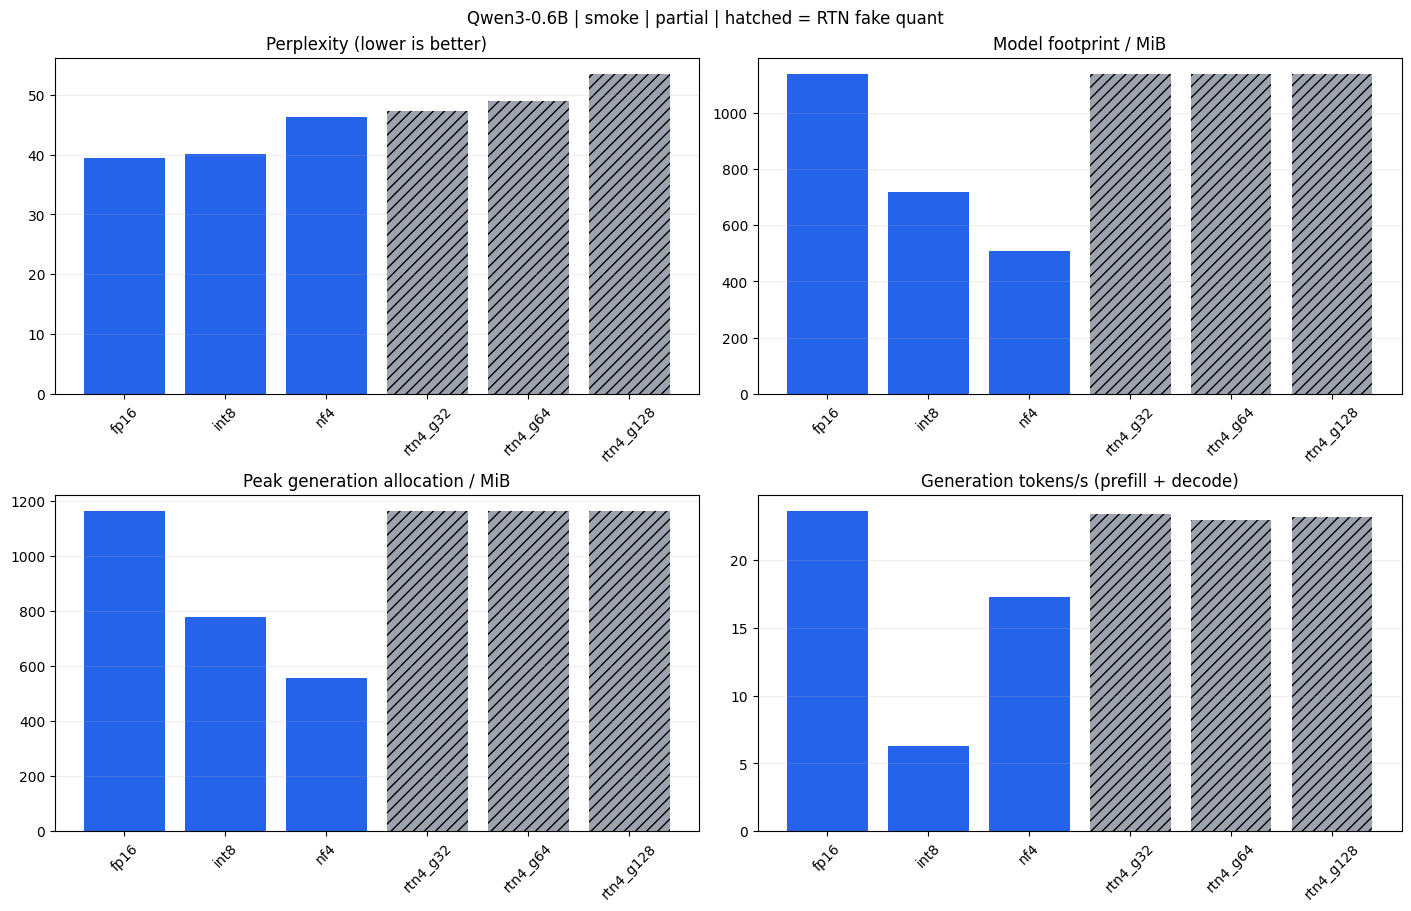

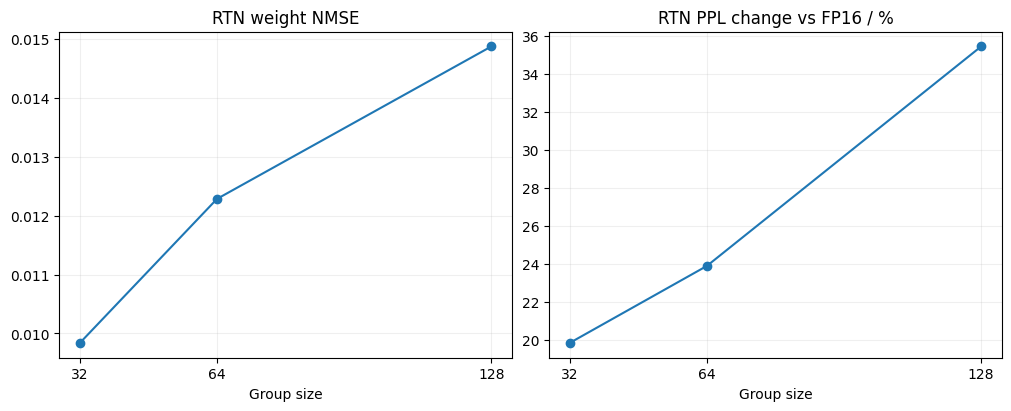

配置,回答,检查
fp16,当然可以！模型量化（Model Quantization）是一种将深度学习模型的参数量从高精度（如 32-bit 或 64-bit）降低到低精度（如 8-bit 或更低）的技术。它的目的是减少模型的计算量和存储需求，同时保持模型的性能。 ### 通俗解释： 量化就像是把一个复杂的模型“简化”成更小的版本。比如，一个原本需要 100 个参数的神经网络，现在变成 10 个参数，但功能和性能几乎一样。 ### 例子： 假设你有一个非常复杂的神经网络，,需人工核对
int8,当然可以！模型量化（Model Quantization）是一种将深度学习模型的参数量从高精度（如 32-bit）降低到低精度（如 8-bit）的技术，目的是减少模型的计算量和存储需求，同时保持模型的性能。 ### 通俗解释： 量化就是把模型的参数“压缩”一下，把原来的高精度参数变成低精度的数值，这样模型的大小变小了，但计算速度和处理能力也变快了。 ### 例子： 比如，一个原来的模型有 1000 个参数，每个参数是 32,需人工核对
nf4,模型量化是一种将模型的参数和权重从浮点数（如 float、double、float32、float64 等）转换为更小的整数格式（如 int8、int4、int16 等）的技术，目的是降低模型的计算需求，从而在资源有限的设备上运行模型，比如手机、嵌入式设备等。 ### 举例说明： 比如，一个模型有 1000 个参数，每个参数是 float 类型，那么在模型量化后，这些参数可能被转换为 8 位的整数，这样,需人工核对
rtn4_g32,当然可以，用通俗的中文解释一下： **模型量化**，指的是对模型的参数进行“量化”处理，也就是把模型的某些参数（比如浮点数）转换为整数，这样可以减少精度损失，同时保留模型的表达能力。 --- ### 例子： 比如，一个模型原本用的是浮点数来表示参数，但为了精度，我们把它转换成了整数。这样在计算的时候，结果就和原来一样，但精度更高了。 比如，一个用浮点数表示的模型，转换成整数后，结果和原来一样，但精度更高了,需人工核对
rtn4_g64,当然可以！模型量化（Model Quantization）是一种技术，用于降低模型的参数量和计算复杂度，同时保持模型的性能和精度。 ### 模型量化的作用： 1. **降低参数量**：通过将模型的权重和一些额外的“可选参数”（如梯度）从浮点数（如 32/64）转换为更小的整数（如 8/16），从而减少内存和计算需求。 2. **保持精度**：虽然参数量减少，但模型的性能（如推理速度、精度）通常不受影响。,需人工核对
rtn4_g128,当然可以！以下是关于“模型量化”的通俗解释： --- ### 模型量化（Model Quantization）： 指的是将模型中的参数（如权重、激活值等）从浮点（float）转换为整数（int）的一种技术。它的目的是减少模型的参数数量，从而降低计算复杂度。 --- ### 举例： 比如，一个深度学习模型有1000个参数，如果用浮点表示，每个参数大约需要64位（即64个字节），总共需要64000个字节。 但如果用整数表示，每个参数可能,需人工核对
配置,回答,检查
fp16,计算 17 × 23 的整数答案是： **421**,未通过
int8,计算 $17 \times 23$ 的整数答案是： $$ 17 \times 23 = 391 $$ 所以，最终答案是： $$ \boxed{391} $$,未通过
nf4,17 × 23 = 391 所以，答案是：**391**。,未通过


以下方法失败，未纳入图表或排名：
gptq4_g128 ValueError Virtual pool 'model_loader:cpu' requests 2 workers but parent 'cpu' only has 1
awq4_g128 ValueError Selected backend `BACKEND.AWQ_GEMM_TRITON` with kernel `AwqGEMMTritonLinear` cannot pack quantized weights for format `FORMAT.GEMM`.
报告目录： /content/quant_results/20261015T041306667650Z
量化 checkpoint 目录（不含在报告 ZIP 中）： /content/quant_checkpoints/20261015T041306667650Z


In [7]:
# quantization-cell: summary
import csv
import html
from IPython.display import HTML, Markdown, display


def comparison_rows(results):
    baseline = next((row for row in results if row["mode"] == "fp16"), None)
    if baseline is None:
        raise ValueError("没有成功的 FP16 基线，不能计算相对指标。")
    summary = []
    for row in results:
        if row["scored_tokens"] != baseline["scored_tokens"]:
            raise ValueError("评测计分 token 数不同，不能直接比较。")
        fake = row["representation"] == "fake_quant_fp16"
        summary.append({
            "mode": row["mode"], "representation": row["representation"],
            "group_size": row["group_size"], "ppl": row["ppl"],
            "ppl_delta_pct": 100 * (row["ppl"] / baseline["ppl"] - 1),
            "logits_kl_vs_fp16": row["logits_kl_vs_fp16"],
            "weight_nmse": row.get("weight_nmse"),
            "model_footprint_mib": row["model_footprint_mib"],
            "peak_generation_allocated_mib": row["peak_generation_allocated_mib"],
            "generation_tokens_per_s": row["generation_tokens_per_s"],
            "speedup_vs_fp16": None if fake else row["generation_tokens_per_s"] / baseline["generation_tokens_per_s"],
            "preparation_seconds": row["preparation_seconds"],
            "checkpoint_weights_mib": row.get("checkpoint_weights_mib"),
            "rule_checks": f"{row['rule_checks_passed']}/{row['rule_checks_total']}",
            "scored_tokens": row["scored_tokens"],
        })
    return summary


if results:
    summary = comparison_rows(results)
    columns = list(summary[0])
    with (OUTPUT_DIR / "summary.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=columns)
        writer.writeheader()
        writer.writerows(summary)
    save_json("summary.json", summary)
    shown = ["mode", "ppl", "ppl_delta_pct", "logits_kl_vs_fp16", "weight_nmse",
             "model_footprint_mib", "peak_generation_allocated_mib", "generation_tokens_per_s",
             "speedup_vs_fp16", "preparation_seconds", "rule_checks"]
    def format_value(value):
        return "—" if value is None else (f"{value:.5g}" if isinstance(value, float) else str(value))
    table = "| " + " | ".join(shown) + " |\n| " + " | ".join(["---"] * len(shown)) + " |\n"
    for row in summary:
        table += "| " + " | ".join(format_value(row[key]) for key in shown) + " |\n"
    display(Markdown(f"**运行状态：{metadata['status']}；完成 {len(results)}/{len(PLAN)} 个配置。**\n\n" + table))
    display(Markdown("PPL、KL 越低越好；`rule_checks` 仅为两道固定题的严格格式/答案检查，不是综合能力分数。"
                     "RTN 的速度是 FP16 伪量化路径，不计 INT4 加速比。"))

    import matplotlib.pyplot as plt
    names = [row["mode"] for row in summary]
    colors = ["#9ca3af" if row["representation"] == "fake_quant_fp16" else "#2563eb" for row in summary]
    figure, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
    for ax, key, title in zip(axes.flat,
        ["ppl", "model_footprint_mib", "peak_generation_allocated_mib", "generation_tokens_per_s"],
        ["Perplexity (lower is better)", "Model footprint / MiB", "Peak generation allocation / MiB",
         "Generation tokens/s (prefill + decode)"]):
        bars = ax.bar(names, [row[key] for row in summary], color=colors)
        for bar, row in zip(bars, summary):
            if row["representation"] == "fake_quant_fp16":
                bar.set_hatch("///")
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.2)
    figure.suptitle(f"Qwen3-0.6B | {PROFILE} | {metadata['status']} | hatched = RTN fake quant")
    figure.savefig(OUTPUT_DIR / "comparison.png", dpi=160)
    plt.show()
    plt.close(figure)
    rtn_rows = sorted((row for row in summary if row["representation"] == "fake_quant_fp16"),
                      key=lambda row: row["group_size"])
    if rtn_rows:
        figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
        for ax, key, title in zip(axes, ["weight_nmse", "ppl_delta_pct"],
                                  ["RTN weight NMSE", "RTN PPL change vs FP16 / %"]):
            ax.plot([row["group_size"] for row in rtn_rows], [row[key] for row in rtn_rows], marker="o")
            ax.set_xticks([row["group_size"] for row in rtn_rows])
            ax.set_xlabel("Group size")
            ax.set_title(title)
            ax.grid(alpha=0.2)
        figure.savefig(OUTPUT_DIR / "rtn_groups.png", dpi=160)
        plt.show()
        plt.close(figure)

    # Render model outputs as escaped plain text; they must not become executable HTML.
    parts = ["<h3>固定中文题：并排核对</h3>"]
    for task in QUALITY_TASKS:
        parts.append(f"<h4>{html.escape(task['id'])}</h4><p>{html.escape(task['prompt'])}</p>")
        parts.append("<table><tr><th>配置</th><th>回答</th><th>检查</th></tr>")
        for mode, samples in quality.items():
            sample = next(item for item in samples if item["id"] == task["id"])
            status = "需人工核对" if sample["passed"] is None else ("通过" if sample["passed"] else "未通过")
            parts.append(f"<tr><td>{html.escape(mode)}</td><td><pre style='white-space:pre-wrap'>"
                         f"{html.escape(sample['answer'])}</pre></td><td>{status}</td></tr>")
        parts.append("</table>")
    report = "<!doctype html><meta charset='utf-8'>" + "\n".join(parts)
    (OUTPUT_DIR / "quality_comparison.html").write_text(report, encoding="utf-8")
    display(HTML(report))
else:
    summary = []
    print("没有成功的结果，请查看 failures.json 中的 FP16 错误。")

if failures:
    print("以下方法失败，未纳入图表或排名：")
    for failure in failures:
        print(failure["mode"], failure["type"], failure["message"])
print("报告目录：", OUTPUT_DIR)
print("量化 checkpoint 目录（不含在报告 ZIP 中）：", ARTIFACT_DIR)

## 下载结果后释放 GPU

下一个单元会下载一个小型 ZIP，包含指标、CSV、PNG、中文回答 HTML、校准 token、模型/数据提交号、执行代码和实际依赖版本。
**GPTQ/AWQ 权重在独立的 `ARTIFACT_DIR` 中，不包含在小型 ZIP 内；要保留模型请另行备份该目录。**
如果浏览器不触发下载，使用 Colab 左侧文件栏下载该 ZIP。

随后选择 **运行时 → 断开连接并删除运行时**。
在 VS Code 扩展中可以使用 `Colab: Remove Server`；确认服务器已移除。
关闭标签页不等同于主动释放运行时。

长任务可在开始前自行挂载 Drive，并将 `OUTPUT_DIR` 改为 Drive 下的结果目录；
模型和数据缓存仍建议留在 `/content`，只把小型结果和检查点写入 Drive。

In [8]:
# quantization-cell: download
import shutil
from google.colab import files

archive = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("下载文件：", archive)
files.download(archive)

下载文件： /content/quant_results/20261015T041306667650Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 如何读对照结果

1. 默认运行 8 个配置。先用 `PROFILE="smoke"` 确认各方法成功，再切换 `full`；不同 profile 的 PPL 不直接互比。
2. `summary.csv` / `comparison.png` 比较质量、显存、速度；`rtn4_g*_layer_errors.json` 比较三种分组的权重误差。
3. 在相同分组 128 下对照 RTN、GPTQ、AWQ 的 PPL、logits KL 和中文回答。权重分布被重新缩放后，权重 MSE 不宜跨算法直接排名。
4. `quality_comparison.html` 并排保留回答。两道自动检查题只能排错，不能替代完整任务基准。
5. `results.json` 记录真实层类型、校准/保存/重载耗时和各次计时；少量校准样本下 GPTQ/AWQ 不保证优于 RTN。
6. `status=partial` 表示有方法失败，已成功的结果仍可下载；先解决 `failures.json` 再做完整对比。
7. 要减少后续试验范围，可以关闭 `RUN_RTN` / `RUN_GPTQ` / `RUN_AWQ`；正式比较仍需相同模型、数据和推理设置。
8. 下一轮可以把 `PTQ_GROUP_SIZE` 改为 32 或 64，或增加校准数据；一次只改一个变量。所有配置始终从原始权重开始。

量化不保证加速。这里的 GPTQ/AWQ 数据是特定 Triton 后端在当前 GPU 上的结果，不代表所有部署框架的最优性能。
本 Notebook 不建立 SSH 服务，结束后请备份结果并移除 Colab 服务器。